# Chapter 17 | Worked solutions

*Designing Reproducible Evaluations*

These twelve solutions connect the question being asked to the unit counted,
the cost of a mistake, and the uncertainty of a comparison. The same predictions
can lead to different conclusions when the denominator or the decision cost changes.
Small arrays make each step inspectable. These fixtures teach evaluation mechanics;
they are not evidence about the quality of a deployed model.

Run this notebook inside `transformers-book`, using a Python kernel with
`requirements.txt` and Matplotlib installed. Run every cell from top to bottom.
The examples use CPU NumPy arrays and fixed random seeds; no models or datasets
are downloaded. The written PDF contains every worked explanation and figure;
the notebook PDF also includes the code and saved results.

In [1]:
from pathlib import Path
import sys
import platform
import numpy as np
import matplotlib
import matplotlib.pyplot as plt

%matplotlib inline
for repo_root in (Path.cwd(), *Path.cwd().parents):
    if (repo_root / "examples/ch17_evaluation/model.py").is_file():
        sys.path.insert(0, str(repo_root))
        break
else:
    raise FileNotFoundError("Open this notebook inside transformers-book.")

from examples.ch17_evaluation.model import (
    binary_metrics, paired_accuracy_bootstrap, reliability_bins, split_by_group,
)
plt.rcParams.update({"figure.figsize": (8, 4), "font.size": 11,
                     "axes.spines.top": False, "axes.spines.right": False})
print("Python", platform.python_version())
print("NumPy", np.__version__, "Matplotlib", matplotlib.__version__)

Python 3.12.14
NumPy 2.5.4 Matplotlib 3.11.2


## 1. Choose an evaluation unit

The short conversation has one correct check out of one. The long conversation
has four correct checks out of five. Count all checks equally to get
$(1+4)/(1+5)=5/6\approx83.3\%$. The long conversation receives five times the weight.

Give each conversation equal weight by first computing its own accuracy:
$(1+4/5)/2=0.9=90\%$. This answers how accurate the average conversation is.
It still allows mistakes within a conversation. For complete-request success,
give a conversation a 1 only if every check succeeds. The short conversation
succeeds and the long one fails, giving $(1+0)/2=50\%$.

The same outcomes support three answers because the questions differ.
If the promise is to handle the entire request correctly, the last measure
is the one that directly checks that promise.

In [2]:
checks = [np.array([1]), np.array([1, 1, 1, 1, 0])]
per_check = np.concatenate(checks).mean()
mean_conversation = np.mean([c.mean() for c in checks])
all_correct = np.mean([c.all() for c in checks])
np.testing.assert_allclose([per_check, mean_conversation, all_correct],
                           [5/6, .9, .5])
print(f"Per check: {per_check:.3%}")
print(f"Mean conversation accuracy: {mean_conversation:.1%}")
print(f"Complete-conversation success: {all_correct:.1%}")

Per check: 83.333%
Mean conversation accuracy: 90.0%
Complete-conversation success: 50.0%


## 2. Compare two kinds of error

Treat UPDATE as positive. Of six real updates, A finds three and B finds five.
Thus A misses three and B misses one. Of fourteen lookups, A falsely flags one
and B falsely flags four, leaving thirteen and ten true negatives respectively.

| Quantity | A | B |
| :-- | --: | --: |
| True positives | 3 | 5 |
| False negatives | 3 | 1 |
| False positives | 1 | 4 |
| True negatives | 13 | 10 |
| Accuracy | $16/20=0.80$ | $15/20=0.75$ |
| Precision | $3/4=0.75$ | $5/9\approx0.5556$ |
| Recall | $3/6=0.50$ | $5/6\approx0.8333$ |

Accuracy divides all correct predictions by 20. Precision divides the found
updates by all predicted updates; recall divides them by all six real updates.
The denominators describe different populations.

Multiply each error count by its cost:

$$
C_A=3c_{\mathrm{miss}}+c_{\mathrm{false}},\qquad
C_B=c_{\mathrm{miss}}+4c_{\mathrm{false}}.
$$

B saves two misses while adding three false alarms. Therefore $C_B<C_A$ exactly
when $2c_{\mathrm{miss}}>3c_{\mathrm{false}}$, or
$c_{\mathrm{miss}}/c_{\mathrm{false}}>3/2$. They tie at $3/2$; A costs less below it.
With costs 4 and 1, A costs 13 units and B costs 8. B can have lower accuracy
and still be preferable for the stated error costs.

In [3]:
truth20 = np.array([1]*6 + [0]*14)
pred_a20 = np.array([1]*3 + [0]*3 + [1] + [0]*13)
pred_b20 = np.array([1]*5 + [0] + [1]*4 + [0]*10)
for name, prediction in [("A", pred_a20), ("B", pred_b20)]:
    metrics = binary_metrics(truth20, prediction)
    cost = 4*metrics["fn"] + metrics["fp"]
    print(name, {k: metrics[k] for k in ("tp", "fn", "fp", "tn")})
    print("  accuracy, precision, recall:",
          [round(metrics[k], 6) for k in ("accuracy", "precision", "recall")])
    print("  cost for miss=4, false=1:", cost)
assert 3*1.5 + 1 == 1.5 + 4

A {'tp': 3, 'fn': 3, 'fp': 1, 'tn': 13}
  accuracy, precision, recall: [0.8, 0.75, 0.5]
  cost for miss=4, false=1: 13
B {'tp': 5, 'fn': 1, 'fp': 4, 'tn': 10}
  accuracy, precision, recall: [0.75, 0.555556, 0.833333]
  cost for miss=4, false=1: 8


## 3. Make two reliability points

Keep every score paired with its label. The lower bin contains scores
$(0.1,0.2,0.4)$ and labels $(0,1,0)$, so its point is
$(0.7/3,1/3)=(7/30,1/3)\approx(0.2333,0.3333)$.
The upper bin contains scores $(0.6,0.8,0.9)$ and labels $(1,1,0)$, giving
$(2.3/3,2/3)=(23/30,2/3)\approx(0.7667,0.6667)$.
The upper bin has a mean score above its observed positive rate.

For the binary Brier score, square the error on each original message before
averaging. The six squared errors are $(0.01,0.64,0.16,0.16,0.04,0.81)$:

$$
\operatorname{Brier}=\frac{1.82}{6}\approx0.3033.
$$

A constant probability of 0.5 incurs error 0.25 on every example, so its score
is 0.25, which is lower. Three of the six labels are positive, so the constant
predictor also has a single empirical reliability point at $(0.5,0.5)$.
It matches the overall frequency but does not distinguish any cases.

Using UPDATE for scores at least 0.5, the original scores give four correct
labels out of six; the constant predictor gives three. Better label accuracy
and better probability quality need not pick the same model. These six cases
illustrate the arithmetic; they cannot establish calibration on future traffic.

In [4]:
scores6 = np.array([.1, .2, .4, .6, .8, .9])
labels6 = np.array([0, 1, 0, 1, 1, 0])
count6, mean6, rate6, brier6 = reliability_bins(labels6, scores6, [0, .5, 1])
constant6 = np.full(6, .5)
constant_brier = np.mean((constant6-labels6)**2)
np.testing.assert_allclose(mean6, [7/30, 23/30])
np.testing.assert_allclose(rate6, [1/3, 2/3])
np.testing.assert_allclose([brier6, constant_brier], [1.82/6, .25])
print("Bin points:", list(zip(mean6.round(6).tolist(), rate6.round(6).tolist())))
print(f"Brier: scores {brier6:.6f}, constant {constant_brier:.6f}")
print("Thresholded accuracy:", np.mean((scores6 >= .5) == labels6),
      np.mean((constant6 >= .5) == labels6))

Bin points: [(0.233333, 0.333333), (0.766667, 0.666667)]
Brier: scores 0.303333, constant 0.250000
Thresholded accuracy: 0.6666666666666666 0.5


## 4. Resample paired outcomes

The original differences are $(0,1,1,-1,0)$, whose mean is $1/5=0.20$.
The one-based IDs $(2,2,4,5,1)$ select differences $(1,1,-1,0,0)$,
also with mean $1/5$. Their equality is a coincidence of this particular draw.
Duplicates must repeat both models' outcomes on the same example.

Separate lists destroy the comparison on shared examples. If A and B make
identical predictions, a paired resample always has gap zero. Independent
lists could give B five easy cases and A five hard cases and produce an
apparent gap of 1 despite their identical predictions. A paired draw preserves
this dependence and the exact cancellation when the systems agree.

In [5]:
d5 = np.array([0, 1, 1, -1, 0])
draw5 = np.array([2, 2, 4, 5, 1]) - 1  # Python uses zero-based indices.
np.testing.assert_allclose([d5.mean(), d5[draw5].mean()], [.2, .2])
print("Original / sampled mean:", d5.mean(), d5[draw5].mean())
same_correctness = np.array([1, 1, 0, 0, 1])
paired_gap = (same_correctness[draw5] - same_correctness[draw5]).mean()
unpaired_gap = same_correctness[[0]*5].mean() - same_correctness[[2]*5].mean()
print("Identical models: paired gap", paired_gap,
      "but a possible separate-list gap", unpaired_gap)

Original / sampled mean: 0.2 0.2
Identical models: paired gap 0.0 but a possible separate-list gap 1.0


## 5. Turn probabilities into decisions

Predicting UPDATE risks a false alarm when the message is really a lookup.
At $p=0.3$, that expected cost is $1(1-0.3)=0.7$. Predicting LOOKUP risks a
missed update, with expected cost $4(0.3)=1.2$. Choose UPDATE, even though
UPDATE is the less probable class.

For general positive costs, compare the two expectations and solve for $p$:

$$
c_{\mathrm{false}}(1-p)<c_{\mathrm{miss}}p
\quad\Longleftrightarrow\quad
p>\frac{c_{\mathrm{false}}}{c_{\mathrm{false}}+c_{\mathrm{miss}}}.
$$

The threshold is $1/(1+4)=0.2$. At equality, both actions cost 0.8 in expectation.
One valid tie rule is to choose UPDATE when $p\geq0.2$; record that convention.
The derivation assumes correct decisions cost zero and that the probabilities
and constant error costs describe the target population. Calibration within
coarse bins alone does not verify these assumptions for every input.

Use validation predictions to fit a calibration mapping or tune a threshold.
Freeze these choices before evaluating the test set. If validation cases are
reused repeatedly to tune many choices, account for that selection, for example
with additional held-out validation data. Changing deployment conditions can
require fresh validation; the arithmetic does not guarantee stable costs or probabilities.

In [6]:
miss_cost, false_cost, probability = 4.0, 1.0, .3
threshold = false_cost / (false_cost + miss_cost)
update_cost = false_cost*(1-probability)
lookup_cost = miss_cost*probability
print(f"Threshold {threshold:.2f}; UPDATE cost {update_cost:.2f}; "
      f"LOOKUP cost {lookup_cost:.2f}")
assert update_cost < lookup_cost and probability >= threshold
np.testing.assert_allclose(false_cost*(1-threshold), miss_cost*threshold)
print("Decision: UPDATE. At the threshold, tie goes to UPDATE.")

Threshold 0.20; UPDATE cost 0.70; LOOKUP cost 1.20
Decision: UPDATE. At the threshold, tie goes to UPDATE.


## 6. Check a split by group

Suppose each row is a message and its group ID identifies the
customer who sent it. Customer 1 sent the first two messages.
If those messages go into different splits, the model can learn
customer-specific patterns in training and encounter them again
during evaluation. To evaluate on held-out customers, assign each
customer to one split and send all of that customer's rows there.

The eight rows have group IDs $(1,1,2,3,3,4,5,5)$, so there are
five distinct groups. Give `split_by_group` the group counts
$(3,1,1)$ for train, validation, and test, with seed 7. The helper
shuffles the distinct IDs and takes the first three for train,
the next one for validation, and the last one for test. It then
finds the original row indices for the IDs in each split.

In [7]:
from examples.ch17_evaluation.model import split_by_group

split_group_ids = np.array([1, 1, 2, 3, 3, 4, 5, 5])
split_group_counts = (3, 1, 1)
split_seed = 7
split_rows = split_by_group(
    split_group_ids, split_group_counts, seed=split_seed
)

split_names = ("Train", "Validation", "Test")
split_groups = [
    set(split_group_ids[rows].tolist()) for rows in split_rows
]
shuffled_ids = np.random.default_rng(split_seed).permutation(
    np.unique(split_group_ids)
)
print("Seeded group order", shuffled_ids.tolist())
for name, rows, groups in zip(split_names, split_rows, split_groups):
    print(f"{name:<10} rows {rows.tolist()}, groups {sorted(groups)}")
    print(f"{'':10} {len(rows)} row(s), {len(groups)} group(s)")

train_groups, validation_groups, test_groups = split_groups
assert train_groups.isdisjoint(validation_groups)
assert train_groups.isdisjoint(test_groups)
assert validation_groups.isdisjoint(test_groups)
assert tuple(map(len, split_groups)) == split_group_counts
assert tuple(map(len, split_rows)) == (6, 1, 1)
np.testing.assert_array_equal(
    np.sort(np.concatenate(split_rows)),
    np.arange(len(split_group_ids)),
)
print("The groups are disjoint and every row appears once.")

Seeded group order [3, 1, 5, 2, 4]
Train      rows [0, 1, 3, 4, 6, 7], groups [1, 3, 5]
           6 row(s), 3 group(s)
Validation rows [2], groups [2]
           1 row(s), 1 group(s)
Test       rows [5], groups [4]
           1 row(s), 1 group(s)
The groups are disjoint and every row appears once.


Train gets groups $\{1,3,5\}$, validation gets $\{2\}$, and test
gets $\{4\}$. The row indices start at zero. In train, rows 0
and 1 belong to group 1, rows 3 and 4 to group 3, and rows 6
and 7 to group 5. The seeded order sets membership. The
returned rows appear in their original order.

Each of the three train groups supplies two rows, giving six
training rows. The validation and test groups each supply one
row. Thus the split has group counts $(3,1,1)$ and row counts
$(6,1,1)$. A quota in groups gives a row count that depends on
the sizes of the selected groups.

## 7. Inspect an empty bin

Imagine four messages scored for whether they are updates.
The scores 0 and 0.1 belong to messages that are lookups
(label 0). The scores 0.9 and 1 belong to updates (label 1).
We want to compare the scores with how often updates actually
occur among messages with similar scores.

Use edges $(0,0.25,0.75,1)$. Each bin includes its left edge
and excludes its right edge, with one exception. The last bin
also includes 1, so every valid probability belongs to a bin.
A score exactly equal to 0.25 goes in the middle bin, and a
score exactly equal to 0.75 goes in the last bin.

In [8]:
from examples.ch17_evaluation.model import reliability_bins

bin_labels = np.array([0, 0, 1, 1])
bin_scores = np.array([0.0, 0.1, 0.9, 1.0])
bin_edges = np.array([0.0, 0.25, 0.75, 1.0])
counts, mean_scores, positive_rates, brier = reliability_bins(
    bin_labels, bin_scores, bin_edges
)
intervals = ("[0, 0.25)", "[0.25, 0.75)", "[0.75, 1]")

print(f"{'Bin':<13} {'Count':>5} {'Mean score':>12} {'Positive rate':>15}")
for interval, count, mean, rate in zip(
    intervals, counts, mean_scores, positive_rates
):
    print(f"{interval:<13} {count:>5} {mean:>12.2f} {rate:>15.2f}")
print(f"Brier score {brier:.3f}")

np.testing.assert_array_equal(counts, [2, 0, 2])
np.testing.assert_allclose(mean_scores[[0, 2]], [0.05, 0.95])
np.testing.assert_allclose(positive_rates[[0, 2]], [0.0, 1.0])
assert np.isnan(mean_scores[1]) and np.isnan(positive_rates[1])
np.testing.assert_allclose(brier, 0.005)

Bin           Count   Mean score   Positive rate
[0, 0.25)         2         0.05            0.00
[0.25, 0.75)      0          nan             nan
[0.75, 1]         2         0.95            1.00
Brier score 0.005


A reliability plot puts the mean predicted probability on
the horizontal axis and the fraction of positive labels on
the vertical axis. Use the bins whose counts are positive.

| Bin | Scores | Mean probability | Positive fraction | Plot point |
| :-- | :-- | --: | --: | :-- |
| $[0,0.25)$ | $0,0.1$ | $(0+0.1)/2=0.05$ | $0/2=0$ | $(0.05,0)$ |
| $[0.25,0.75)$ | None | Undefined | Undefined | Omit |
| $[0.75,1]$ | $0.9,1$ | $(0.9+1)/2=0.95$ | $2/2=1$ | $(0.95,1)$ |

The low bin is 0.05 below the ideal diagonal $y=x$ because
the mean score exceeds the observed fraction. The high bin
is 0.05 above it because the observed fraction exceeds the
mean score. Each point summarizes two examples.

In the middle bin, both averages would require dividing by
zero. The helper returns `NaN` for both coordinates to
mark them as undefined. Filling both with zero would draw
a fake perfectly calibrated point at $(0,0)$. Plotting a
zero rate at the bin midpoint, $(0.50,0)$, would instead
suggest that predictions near 0.50 all had negative
outcomes. The data contain no examples in that range.
The low bin's zero rate is a measured $0/2$, whereas the
middle bin's count of zero means its rate is undefined.

The helper also returns the Brier score. It averages the
squared error between each original score and its label.
Here the errors are $0$, $0.01$, $0.01$, and $0$, so the
Brier score is $0.02/4=0.005$.

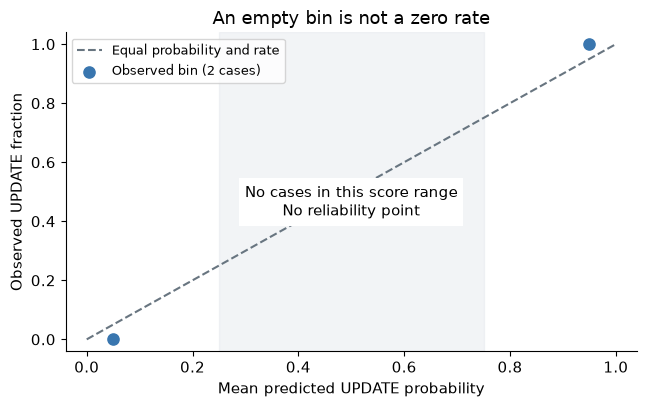

In [9]:
fig, ax = plt.subplots(figsize=(6.6, 4.2))
ax.plot([0, 1], [0, 1], "--", color="#687580", label="Equal probability and rate")
observed_bins = counts > 0
ax.scatter(mean_scores[observed_bins], positive_rates[observed_bins],
           s=65, color="#3976AF", zorder=3, label="Observed bin (2 cases)")
ax.axvspan(.25, .75, color="#DCE2E7", alpha=.35)
ax.text(.50, .42, "No cases in this score range\nNo reliability point", ha="center",
        bbox={"facecolor": "white", "edgecolor": "none", "pad": 4})
ax.set(xlabel="Mean predicted UPDATE probability", ylabel="Observed UPDATE fraction",
       xlim=(-.04, 1.04), ylim=(-.04, 1.04), title="An empty bin is not a zero rate")
ax.legend(loc="upper left", fontsize=9)
fig.tight_layout(); plt.show()

## 8. Change the resampling unit

Models A and B label the same six messages. The first customer sent
two messages, and B gets both right where A gets both wrong. The last
customer sent one message that only A gets right and one that both
models get right. The table keeps the two predictions together for
each message.

| Message | Customer | True label | A | B | Correctness difference |
| --: | --: | --: | --: | --: | --: |
| 1 | 0 | 1 | 0 | 1 | +1 |
| 2 | 0 | 1 | 0 | 1 | +1 |
| 3 | 1 | 0 | 0 | 0 | 0 |
| 4 | 1 | 0 | 1 | 1 | 0 |
| 5 | 2 | 1 | 1 | 0 | $-1$ |
| 6 | 2 | 0 | 0 | 0 | 0 |

On message $i$, the correctness difference $d_i$ is 1 if only B is
right, $-1$ if only A is right, and 0 if both have the same outcome.
The difference in accuracy is the average of these row differences.
A gets three messages right and B gets four, so the observed gap is

$$
\Delta = \frac{4}{6} - \frac{3}{6}
= \frac{1+1+0+0-1+0}{6} = \frac{1}{6}.
$$

A paired bootstrap repeatedly draws a new sample, allowing repeats,
from the observed test set. A row draw keeps A, B, and the true label
together. For example, drawing messages 1, 1, 2, 4, 5, and 6 gives a
gap of $(1+1+1+0-1+0)/6=1/3$ for that draw.

With customer resampling, each draw selects three customers and
brings along every message from each selected customer. For example,
drawing customers 0, 0, and 2 contributes two copies of customer 0's
gain of two correct messages and one copy of customer 2's loss of
one. The gap is $(2+2-1)/6=1/2$. The denominator counts all sampled
messages, including repeats. This gives each sampled message equal
weight even if customers have different message counts.

In [10]:
from examples.ch17_evaluation.model import paired_accuracy_bootstrap

bootstrap_truth = np.array([1, 1, 0, 0, 1, 0])
bootstrap_a = np.array([0, 0, 0, 1, 1, 0])
bootstrap_b = np.array([1, 1, 0, 1, 0, 0])
customer_ids = np.array([0, 0, 1, 1, 2, 2])

correct_a = bootstrap_a == bootstrap_truth
correct_b = bootstrap_b == bootstrap_truth
differences = correct_b.astype(int) - correct_a.astype(int)
observed_gap = differences.mean()
print(f"Correct messages: A {correct_a.sum()}, B {correct_b.sum()}")
print(f"B minus A by message: {differences.tolist()}")
print(f"Observed accuracy gap: {observed_gap:+.6f}")

Correct messages: A 3, B 4
B minus A by message: [1, 1, 0, 0, -1, 0]
Observed accuracy gap: +0.166667


Compute 4,000 resampled gaps for each method with seed 5. The 95%
percentile interval uses the 2.5th and 97.5th percentiles of those
gaps. Both calls report the same observed gap because they score the
same original six messages.

In [11]:
for unit, groups in (("Message", None), ("Customer", customer_ids)):
    point, (low, high) = paired_accuracy_bootstrap(
        bootstrap_truth, bootstrap_a, bootstrap_b,
        repeats=4000, confidence=0.95, seed=5, groups=groups,
    )
    assert np.isclose(point, observed_gap)
    print(f"{unit:<8} gap {point:+.6f}   95% [{low:+.6f}, {high:+.6f}]")

Message  gap +0.166667   95% [-0.333333, +0.666667]
Customer gap +0.166667   95% [-0.500000, +1.000000]


Both methods estimate a gain of 16.7 percentage points for B on these
six messages. The interval widens from $[-1/3, 2/3]$ for messages
to $[-1/2, 1]$ for customers. With customer resampling, the first
customer's two gains always travel together. A draw with three copies
of that customer has a gap of $+1$. A draw with three copies of the
last customer has a gap of $-1/2$.

Use the customer bootstrap when messages from a customer can be
dependent and customers are the independent units. For example, two
messages may use the same wording or discuss the same request. Drawing
customers preserves these connections. Both intervals span zero and
allow sizable changes in either direction. Six messages from just
three customers give little information about the gap for new
customers. These intervals describe sensitivity to the evaluation
sample for the two fixed checkpoints. To study variation across
training runs, compare independently trained checkpoints.

The intervals are approximate percentile summaries, especially fragile with
only three independent customers. Their inclusion of zero does not prove that
A and B are equivalent: they permit substantial gains and losses. Increasing
the 4,000 draws would reduce simulation noise in the percentiles but would not
add independent customers. The nominal 95% level is a repeated-sampling coverage
target, not a posterior probability that the fixed gap lies in this particular interval.

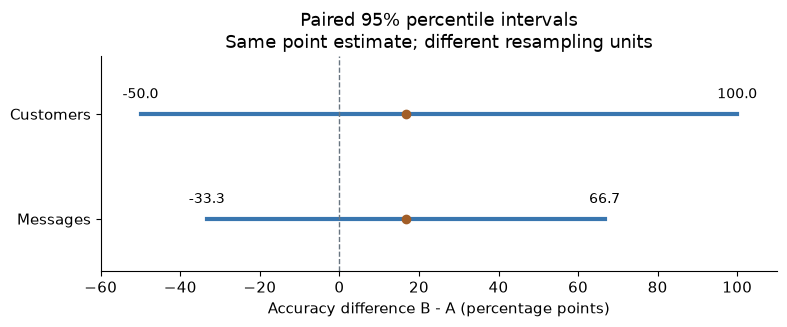

In [12]:
interval_results = []
for label, grouping in [("Messages", None), ("Customers", customer_ids)]:
    point, limits = paired_accuracy_bootstrap(
        bootstrap_truth, bootstrap_a, bootstrap_b,
        repeats=4000, confidence=.95, seed=5, groups=grouping)
    interval_results.append((label, point, limits))
fig, ax = plt.subplots(figsize=(8, 3.4))
for y, (label, point, (low, high)) in enumerate(interval_results):
    ax.plot([low*100, high*100], [y, y], color="#3976AF", lw=3)
    ax.scatter([point*100], [y], color="#A25E27", zorder=3)
    ax.text(low*100, y+.15, f"{low*100:.1f}", ha="center", fontsize=10)
    ax.text(high*100, y+.15, f"{high*100:.1f}", ha="center", fontsize=10)
ax.axvline(0, color="#687580", ls="--", lw=1)
ax.set(yticks=[0, 1], yticklabels=[r[0] for r in interval_results],
       ylim=(-.5, 1.55), xlim=(-60, 110),
       xlabel="Accuracy difference B - A (percentage points)",
       title="Paired 95% percentile intervals\nSame point estimate; different resampling units")
fig.tight_layout(); plt.show()

For the separate unequal-customer example, U contributes one row with difference
$+1$. V contributes three rows whose differences sum to $-2$ and average $-2/3$.
The per-message gap is $(1-2)/(1+3)=-1/4$, favoring A. The equal-customer gap is
$(1-2/3)/2=1/6$, favoring B. Changing the weighting changes the question.

For the sampled customer list $(U,U)$, include U's one message twice. The
per-message numerator is $1+1=2$, the denominator is $1+1=2$, and the gap is 1.
For $(U,V)$ they are $-1$ and 4, giving $-1/4$; for $(V,V)$ they are $-4$ and 6,
giving $-2/3$. Divide by the sampled message count, which need not stay fixed
when group sizes differ. The helper's grouped option retains this per-message target.

In [13]:
customer_differences = [np.array([1]), np.array([-1, -1, 0])]
message_gap = np.concatenate(customer_differences).mean()
customer_gap = np.mean([d.mean() for d in customer_differences])
np.testing.assert_allclose([message_gap, customer_gap], [-.25, 1/6])
print("Per message / per customer:", message_gap, customer_gap)
for draw in [(0, 0), (0, 1), (1, 1)]:
    numerator = sum(customer_differences[i].sum() for i in draw)
    denominator = sum(len(customer_differences[i]) for i in draw)
    print(tuple("UV"[i] for i in draw), "numerator", numerator,
          "denominator", denominator, "gap", numerator/denominator)

Per message / per customer: -0.25 0.16666666666666669
('U', 'U') numerator 2 denominator 2 gap 1.0
('U', 'V') numerator -1 denominator 4 gap -0.25
('V', 'V') numerator -4 denominator 6 gap -0.6666666666666666


## 9. Audit a prediction join (optional)

Suppose the reference file has one row per message and the prediction
file contains the same six messages in a different order. For `m01`,
the correct label is 1 and the model's prediction is also 1. In the
shuffled file the first row belongs to `m04` and predicts 0. Scoring
by position treats that 0 as a mistake on `m01`.

An example ID is a stable key for a message across both files. Keep
the IDs attached while shuffling the prediction records. First score
the values in their current order to see what happens when the keys
are ignored.

In [14]:
from examples.ch17_evaluation.model import binary_metrics

truth_records = [
    ("m01", 1), ("m02", 0), ("m03", 1),
    ("m04", 0), ("m05", 1), ("m06", 0),
]
predictions_in_truth_order = [
    ("m01", 1), ("m02", 1), ("m03", 1),
    ("m04", 0), ("m05", 0), ("m06", 0),
]
shuffle_order = [3, 0, 5, 2, 1, 4]
prediction_records = [
    predictions_in_truth_order[i] for i in shuffle_order
]

print("Position  Label ID  Label  Prediction ID  Prediction")
for position, (label, pred) in enumerate(
    zip(truth_records, prediction_records), start=1
):
    label_id, label_value = label
    pred_id, pred_value = pred
    print(f"{position:>8}  {label_id:>8}  {label_value:>5}  "
          f"{pred_id:>13}  {pred_value:>10}")

truth_by_position = np.array([label for _, label in truth_records])
predictions_by_position = np.array([p for _, p in prediction_records])
order_score = binary_metrics(truth_by_position, predictions_by_position)
print(f"Accuracy by file position: {order_score['accuracy']:.2%}")

Position  Label ID  Label  Prediction ID  Prediction
       1       m01      1            m04           0
       2       m02      0            m01           1
       3       m03      1            m06           0
       4       m04      0            m03           1
       5       m05      1            m02           1
       6       m06      0            m05           0
Accuracy by file position: 33.33%


Both arrays have six values, so `binary_metrics` can compute an
accuracy even when the rows represent different messages. Before
scoring, check for a one-to-one match. Build an index for each file,
rejecting repeated IDs before a dictionary assignment can overwrite a
row. Then compare the key sets in both directions. A reference key
absent from predictions is missing. A prediction key absent from the
reference is unexpected. Once the keys agree, look up every
prediction in the order of the reference IDs.

In [15]:
def unique_by_id(records, source):
    """Index records with one value per nonblank string ID."""
    indexed = {}
    for example_id, value in records:
        if not isinstance(example_id, str) or not example_id.strip():
            raise ValueError(f"{source} has a blank or non-string ID")
        if example_id in indexed:
            raise ValueError(f"{source} has duplicate ID {example_id!r}")
        indexed[example_id] = value
    return indexed


def align_by_id(labels, predictions):
    truth_by_id = unique_by_id(labels, "Label file")
    prediction_by_id = unique_by_id(predictions, "Prediction file")
    missing = sorted(truth_by_id.keys() - prediction_by_id.keys())
    unexpected = sorted(prediction_by_id.keys() - truth_by_id.keys())
    if missing or unexpected:
        raise ValueError(
            f"Missing IDs: {missing}. Unexpected IDs: {unexpected}."
        )
    return (
        np.array(list(truth_by_id.values())),
        np.array([prediction_by_id[key] for key in truth_by_id]),
    )

In [16]:
joined_truth, joined_predictions = align_by_id(
    truth_records, prediction_records
)
joined_score = binary_metrics(joined_truth, joined_predictions)
correct_ids = [
    example_id
    for (example_id, _), is_correct in zip(
        truth_records, joined_truth == joined_predictions
    )
    if is_correct
]
assert correct_ids == ["m01", "m03", "m04", "m06"]
assert np.isclose(order_score["accuracy"], 2 / 6)
assert np.isclose(joined_score["accuracy"], 4 / 6)
print(f"Correct IDs after joining: {', '.join(correct_ids)}")
print(f"Accuracy after joining: {joined_score['accuracy']:.2%}")

Correct IDs after joining: m01, m03, m04, m06
Accuracy after joining: 66.67%


The row-order calculation reports two correct answers out of six. The
ID join recovers four correct answers out of six. Try three broken
prediction files to check that they are rejected before scoring. A
replacement with an unexpected ID or a duplicate can leave the file
with all six rows, so checking the count alone misses both errors.

In [17]:
broken_files = (
    ("Missing", prediction_records[:-1], "Missing IDs: ['m05']"),
    ("Wrong key", prediction_records[:-1] + [("m99", 0)],
     "Unexpected IDs: ['m99']"),
    ("Duplicate", prediction_records[:-1] + prediction_records[:1],
     "Prediction file has duplicate ID 'm04'"),
)
for case, records, expected in broken_files:
    try:
        align_by_id(truth_records, records)
    except ValueError as error:
        assert expected in str(error)
        print(f"{case}: {error}")
    else:
        raise AssertionError(f"{case} should fail before scoring")

Missing: Missing IDs: ['m05']. Unexpected IDs: [].
Wrong key: Missing IDs: ['m05']. Unexpected IDs: ['m99'].
Duplicate: Prediction file has duplicate ID 'm04'


This check also rejects duplicate keys in the reference file. For a
paired model comparison, run the same check for each model's file
against the same reference order before passing the two arrays to the
bootstrap helper.

## 10. Separate length from evidence placement (optional)

Ask for the invoice number for order P27. One report sentence says:
*The total for order P27 was settled under invoice IN-843.* Other orders can
have plausible invoice numbers, but only this sentence answers the question.
Score exact invoice match after a fixed normalization such as trimming whitespace.

Use report-body lengths of 512, 2,048, and 8,192 tokens, with evidence starts
near 10%, 50%, and 90%. Here a token position is a zero-based index. For a
worked layout, suppose the evidence occupies 16 tokens and set its start to
$\lfloor fL\rfloor$, where $L$ is the body length and $f$ the chosen fraction.
The question starts at $q=L$ in these body-relative coordinates. The distance
from the exclusive evidence end to the question is $L-\lfloor fL\rfloor-16$.

| Body tokens | Early: start / distance | Middle: start / distance | Late: start / distance |
| --: | --: | --: | --: |
| 512 | 51 / 445 | 256 / 240 | 460 / 36 |
| 2,048 | 204 / 1,828 | 1,024 / 1,008 | 1,843 / 189 |
| 8,192 | 819 / 7,357 | 4,096 / 4,080 | 7,372 / 804 |

Within a row, keep the body length, question, answer, evidence wording,
scoring rule, and distractor inventory fixed. Reserve neutral spans and swap
the evidence with an equal-token-length span, leaving distractors in place.
Re-tokenize the complete formatted prompt and check the lengths and boundaries:
raw-text swaps do not guarantee identical token counts. Keep instructions fixed
and reserve generation capacity after including the question and any wrappers.
The 16-token span is a layout assumption, not a claim about a specific tokenizer.

In [18]:
lengths = [512, 2048, 8192]
fractions = [.1, .5, .9]
evidence_length = 16
print("Body length: (start, exclusive end, distance to question)")
layout = []
for length in lengths:
    placements = []
    for fraction in fractions:
        start = int(np.floor(fraction*length))
        end = start + evidence_length
        distance = length - end
        assert 0 <= start < end <= length
        placements.append((start, end, distance))
        layout.append((length, start, end, distance))
    print(length, placements)

Body length: (start, exclusive end, distance to question)
512 [(51, 67, 445), (256, 272, 240), (460, 476, 36)]
2048 [(204, 220, 1828), (1024, 1040, 1008), (1843, 1859, 189)]
8192 [(819, 835, 7357), (4096, 4112, 4080), (7372, 7388, 804)]


For the second experiment, hold exactly 128 tokens between the evidence end
and the question. With the same 16-token evidence span, set its start to
$L-128-16$. The starts are 368, 1,904, and 8,048; the exclusive ends are
384, 1,920, and 8,064. The distance is 128 in every case. Insert additional
neutral text before the evidence as the body grows and preserve the suffix after it.
Hold the distractor inventory fixed or explicitly exclude candidate invoice
numbers from the added filler.

Use many underlying reports, vary the correct invoice numbers, and compare
placements on matched reports. Split and resample whole report families,
including their placement variants. Report exact positions, counts per condition,
and failed or truncated inputs. If a model cannot accept a complete prompt,
state the unsupported condition rather than silently dropping or shortening it.
Synthetic retrieval results should be supplemented with realistic reports.

In [19]:
fixed_distance = 128
for length in lengths:
    start = length - fixed_distance - evidence_length
    end = start + evidence_length
    assert length-end == 128 and start >= 0
    print(f"Body {length}: start {start}, end {end}, distance {length-end}")
print("Additional text goes before the evidence; its suffix is preserved.")

Body 512: start 368, end 384, distance 128
Body 2048: start 1904, end 1920, distance 128
Body 8192: start 8048, end 8064, distance 128
Additional text goes before the evidence; its suffix is preserved.


## 11. Test one change at a time (optional)

The supported released-system claim is that the measured configuration of B
has lower response latency than A on the stated workload, device, and software.
Mixer, training data, precision, implementation, and their interactions all
contribute. The result does not isolate the mixer. Quality must also be measured;
a faster system that answers a different task or stops early is not automatically preferable.

For a mixer ablation, build two variants of one model. Keep tokenizer, input
format, training and validation data, training-token count, optimizer policy,
prediction interface, and checkpoint selection rule fixed. Preserve stack depth,
residual width, feed-forward blocks, and output head. Replace the designated
mixer layers. Choose a matching budget, such as model width and training tokens,
and report remaining parameter or compute differences. Give both variants
comparable validation tuning effort; identical learning rates need not be equally suitable.
Use the same declared seed set for multiple runs. Matching seeds is a control,
not proof that different architectures experience identical randomness.

Measure quality on the same examples, including task accuracy, error types,
paired test-sample uncertainty and variation across training runs separately.
For latency, keep device, software, batch size, precision, prompts, and decoding
policy fixed. Warm up, synchronize the relevant device around timed regions,
alternate run order, and report distributions across repeated trials.
Separate time to first token, time per later decoding step, throughput, and
end-to-end latency. Prefill time alone is not user-facing time to first token.

For a controlled timing diagnostic, feed a fixed continuation token sequence
to both models so output length and tokens are matched; report this as a
teacher-forced timing experiment. Also time actual generation under a declared
stopping rule for the deployment result. Use several prompt lengths if storage
or computation is expected to scale with history.

Count live key/value arrays and recurrent or convolutional states that persist
between steps. Separately report reserved capacity, model-weight bytes, and peak
temporary workspace. A smaller persistent history need not mean a smaller
peak or a faster system. The ablation supports a claim about this mixer change
under these controls; the released packages remain a separate systems comparison.

In [20]:
ablation_record = {
    "change": "designated mixer layers",
    "controls": ["tokenizer", "data/split", "training tokens", "precision",
                 "residual width", "tuning effort", "checkpoint rule"],
    "quality": ["paired task outcomes", "error counts", "training-seed variation"],
    "timing": ["first token", "later token", "end-to-end", "throughput"],
    "storage": ["live history", "reserved capacity", "weights", "peak workspace"],
}
for key, value in ablation_record.items():
    print(key + ":", ", ".join(value) if isinstance(value, list) else value)
print("Protocol only: no performance result is claimed.")

change: designated mixer layers
controls: tokenizer, data/split, training tokens, precision, residual width, tuning effort, checkpoint rule
quality: paired task outcomes, error counts, training-seed variation
timing: first token, later token, end-to-end, throughput
storage: live history, reserved capacity, weights, peak workspace
Protocol only: no performance result is claimed.


## 12. Design a reproducibility check (optional)

Two aggregate scores do not reveal which cases each system got right. Start
with the versioned dataset, labeled evaluation rows, and saved split manifest.
For every row, require a stable example ID, its group or connected-family ID,
and assigned split. Record exclusions, provenance, the unit scored, and which
data selected hyperparameters, thresholds, prompts, and checkpoints. Check that
the grouping constraints are disjoint across splits and the test rows match
the frozen manifest. Fine-tuning splits alone cannot rule out pretraining exposure.

Request one raw and parsed prediction per model per example, the class order,
score meaning, decoding settings, threshold, and normalization or parsing rules.
Specify how invalid and missing predictions count. Check unique IDs, exact key
coverage, and the mapping back to gold labels before joining by ID. Replay
parsing and recompute each accuracy, confusion counts, and the difference.
Equal array lengths alone cannot validate the join.

For the paired interval, form B's correctness minus A's on each matched row.
Resample the same rows for both models or draw independent source groups and
include all their rows. Keep the metric's denominator consistent with the
target: a per-message gap divides by the sampled message count, including
repeats. Save the resampling unit, confidence level, seed, draw count, and
quantile convention. Nonlinear metrics require recomputation on each draw.
Record both the number of rows and the number and sizes of independent groups.

Variation across training runs needs separately trained checkpoints and their
per-example predictions, along with initialization/data-order seeds, training
recipes, model revisions, and validation-based selection rules. Evaluate all
declared runs on the same test manifest and report the rule used to summarize
them. The spread across runs and the bootstrap for one fixed pair of checkpoints
answer separate questions. A saved bootstrap seed cannot reproduce a training run.

The small check here reuses the audited ID join from Exercise 9. It returns the
same $4/6$ accuracy, verifies that group IDs remain disjoint across the Exercise 6
splits, and confirms that comparing the same predictions to themselves gives
an exactly zero point and interval. These are useful integrity checks; they
do not replace the requested source files or validate the population sampling.

In [21]:
audit_truth, audit_prediction = align_by_id(truth_records, prediction_records)
audit_metrics = binary_metrics(audit_truth, audit_prediction)
assert np.isclose(audit_metrics["accuracy"], 4/6)
assert all(split_groups[i].isdisjoint(split_groups[j])
           for i in range(3) for j in range(i+1, 3))
identical = paired_accuracy_bootstrap(
    audit_truth, audit_prediction, audit_prediction, repeats=4000, seed=5)
assert identical == (0.0, (0.0, 0.0))
print("Joined accuracy:", audit_metrics["accuracy"])
print("Split groups: disjoint. Identical-model comparison:", identical)
print("Required evidence: split manifest, IDs, raw predictions, recipe, seeds.")

Joined accuracy: 0.6666666666666666
Split groups: disjoint. Identical-model comparison: (0.0, (0.0, 0.0))
Required evidence: split manifest, IDs, raw predictions, recipe, seeds.
